# Diseño factorial de LoRA y comprobación del óptimo

Este notebook contiene los resultados finales de la ampliación: factorial 3 × 2 por duplicado, análisis de interacción, superficie de respuesta, comprobación fuera del dominio y comparación del LoRA seleccionado con DoRA, rsLoRA y LoRA+.

Las cifras se leen de ejecuciones reales de Khipu. Abrirlo no vuelve a entrenar modelos. La tarea, los datos y la implementación inicial se desarrollan en los notebooks 01 y 02. Todos los ejemplos son sintéticos.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
F=ROOT/'factorial'; R=F/'results'
assert (R/'COMPLETE.json').exists(), 'La ampliación no ha terminado.'
read=lambda name: json.loads((R/name).read_text(encoding='utf8'))
plan=json.loads((F/'plan.json').read_text(encoding='utf8'))
experiments=pd.read_csv(R/'experiments.csv')
cells=pd.read_csv(R/'cells.csv')
selection=read('selection.json')['selected']
hardware=read('hardware.json')
display(pd.DataFrame([{'Nodo':hardware['node'],'GPU':hardware['gpu'],'Job':hardware['job_id'],'Rango elegido':selection['rank'],'Alpha elegido':selection['alpha']}]))

,Nodo,GPU,Job,Rango elegido,Alpha elegido
0,g002,NVIDIA RTX A6000,58225,1,32


## 1. Pregunta y diseño

¿A partir de qué rango deja de compensar aumentar la capacidad de LoRA, y depende ese resultado de alpha? Los factores son **r = 2, 8, 32** y **alpha = 8, 32**. Las seis combinaciones se entrenan con **semillas 42 y 43**, una por ronda completa. La semilla sirve como bloque de réplica.

Primero se ejecutan las cuatro esquinas con semilla 42, luego el rango intermedio y después la segunda ronda. Se conserva el presupuesto de 32 actualizaciones y lote efectivo 8. Se cambian únicamente los dos factores y la semilla de la réplica. En LoRA estándar la escala es alpha/r, por lo que se analiza su interacción.

El plan y la regla de selección se fijaron antes de las nuevas ejecuciones. La documentación completa está en `factorial/DISEÑO.md`.

In [2]:
display(pd.DataFrame(plan['execution_order']))
factorial=experiments[(experiments.method=='lora') & experiments['rank'].isin(plan['ranks'])]
assert len(factorial)==12
replicas=factorial.groupby(['rank','alpha']).seed.apply(lambda x: sorted(x)).reset_index()
assert all(x==[42,43] for x in replicas.seed)
display(replicas.rename(columns={'seed':'Semillas de ambas réplicas'}))
print('Total factorial:',len(factorial),'entrenamientos independientes.')

,rank,alpha,seed,phase
0,32,32,42,extremes
1,2,8,42,extremes
2,2,32,42,extremes
3,32,8,42,extremes
4,8,32,42,factorial
5,8,8,42,factorial
6,8,8,43,replica
7,32,8,43,replica
8,2,8,43,replica
9,2,32,43,replica


,rank,alpha,Semillas de ambas réplicas
0,2,8,"[42, 43]"
1,2,32,"[42, 43]"
2,8,8,"[42, 43]"
3,8,32,"[42, 43]"
4,32,8,"[42, 43]"
5,32,32,"[42, 43]"


Total factorial: 12 entrenamientos independientes.


## 2. Mediciones y controles

Todos los nuevos experimentos usan una RTX A6000 del mismo nodo y la misma asignación Slurm. Cada condición recarga el modelo original. La compilación inicial se prepara con una pasada forward/backward sin actualizar pesos, se descartan los gradientes y se restaura la semilla. Su duración se informa por separado.

La memoria es el máximo asignado por PyTorch al proceso, no la memoria total de la GPU. La inferencia usa lote uno, generación sin muestreo y adaptadores sin fusionar. La carga de otros usuarios puede alterar tiempos. El costo es una simulación a USD 1 por hora de entrenamiento, sin incluir cola, descarga o inferencia.

In [3]:
columns=['rank','alpha','seed','validation_f1','test_f1','schema','critical_recall','train_seconds','train_vram_gib','latency_s','warmup_seconds','cost_usd']
display(factorial[columns].sort_values(['rank','alpha','seed']).round(4))
print('Hashes de datos usados:',hardware['data_sha256'])

,rank,alpha,seed,validation_f1,test_f1,schema,critical_recall,train_seconds,train_vram_gib,latency_s,warmup_seconds,cost_usd
1,2,8,42,0.7789,0.8750,1.0,0.875,227.1204,3.2041,1.4142,0.8770,0.0631
8,2,8,43,0.6842,0.8470,1.0,0.875,226.6672,3.2045,1.6437,0.8735,0.0630
2,2,32,42,0.8354,0.8757,1.0,0.875,211.2628,3.2041,1.6298,0.8168,0.0587
9,2,32,43,0.7767,0.8611,1.0,0.875,226.1623,3.2045,1.6522,0.8735,0.0628
5,8,8,42,0.7789,0.8750,1.0,0.875,211.0920,3.2517,1.6149,0.8094,0.0586
6,8,8,43,0.6818,0.8470,1.0,0.875,211.1616,3.2521,1.6135,0.8114,0.0587
4,8,32,42,0.8354,0.8593,1.0,0.875,210.3664,3.2517,1.6218,0.8082,0.0584
11,8,32,43,0.7720,0.8903,1.0,0.875,224.0075,3.2521,1.6461,0.8596,0.0622
3,32,8,42,0.7763,0.8750,1.0,0.875,212.1230,3.4241,1.6267,2.0349,0.0589
7,32,8,43,0.7023,0.8470,1.0,0.875,221.4431,3.4426,1.6457,0.8134,0.0615


Hashes de datos usados: {'test.jsonl': '00456c3731b6d27cb10100fae50feed6e20a27980bb7bc9e73d39a0745b8c31e', 'train.jsonl': '117bac695f81a95f63a9afea03f3e5847e13c6482c70e787250d5084fbc25839', 'validation.jsonl': 'fce3d1bf14103237fdffad7f431490dabd827518d8e3ac55c467714bb3af5609', 'stress.jsonl': 'fe8309c4cdf914df25d3192c885b03c81a61b7cb7193c6f5cde5c8f6e2d34819'}


## 3. Resultados del factorial

La selección usa F1 macro de validación. La prueba y los casos difíciles se reservan para describir desempeño. Cada celda muestra la media de las dos réplicas y sus resultados individuales, evitando ocultar variaciones entre semillas.

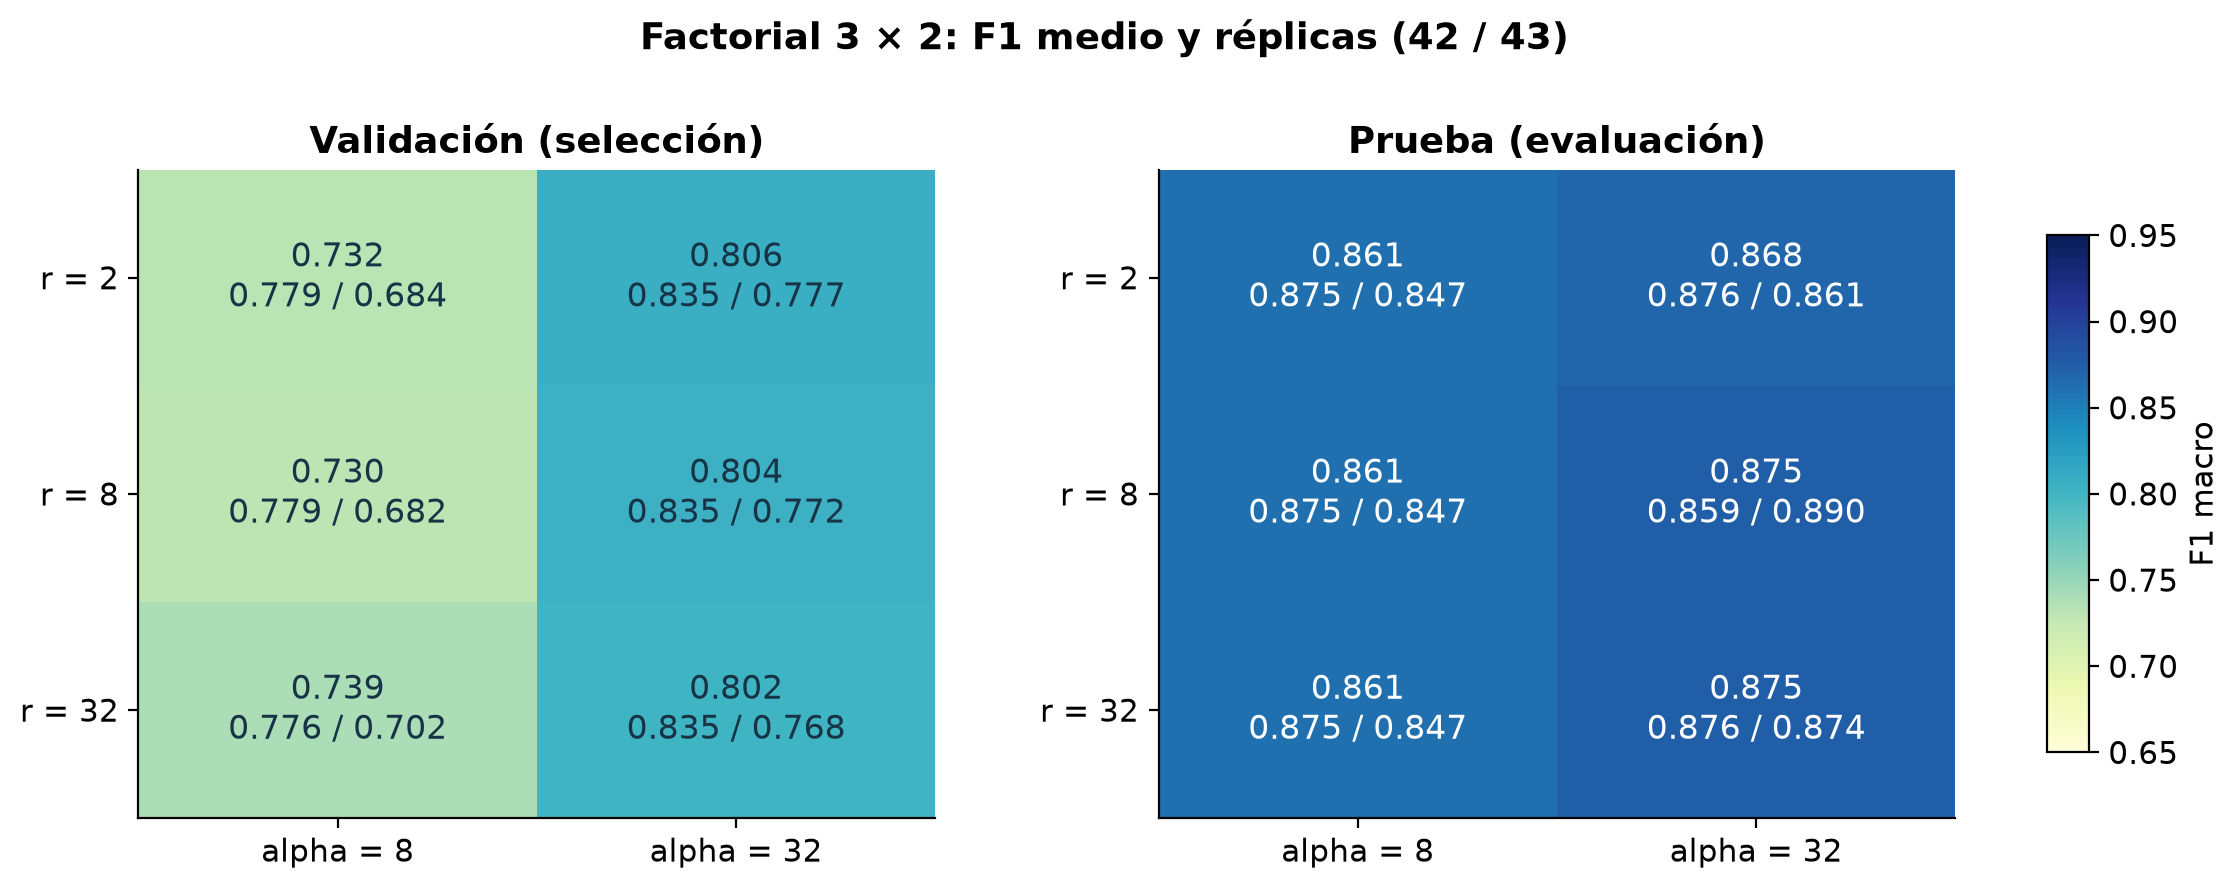

,rank,alpha,n,validation_f1,validation_sd,test_f1,test_sd
0,1,32,2,0.8284,0.0673,0.8915,0.0185
1,2,8,2,0.7315,0.0669,0.8610,0.0198
2,2,32,2,0.8060,0.0415,0.8684,0.0103
3,8,8,2,0.7303,0.0687,0.8610,0.0198
4,8,32,2,0.8037,0.0448,0.8748,0.0219
5,32,8,2,0.7393,0.0523,0.8610,0.0198
6,32,32,2,0.8017,0.0476,0.8747,0.0014
7,64,32,2,0.7856,0.0390,0.8600,0.0011


In [4]:
display(Image(filename=str(F/'figures/factorial_heatmap.png')))
display(cells[cells.method=='lora'][['rank','alpha','n','validation_f1','validation_sd','test_f1','test_sd']].round(4))

## 4. Efectos principales e interacción

Se ajusta una superficie cuadrática en log2(r), alpha como factor de dos niveles y sus interacciones, incorporando el bloque de semilla. Los grados de libertad residuales son pequeños: las pruebas F son exploratorias y deben interpretarse junto con las réplicas y los costos. Con dos niveles no se estima una curvatura de alpha.

La interacción indica si el cambio asociado a r depende de alpha. Los puntos son mediciones y las líneas muestran el ajuste; la extensión discontinua queda fuera del dominio inicial.

F1_validación = b0+b1*x+b2*q+b3*z+b4*x*z+b5*q*z+b6*bloque; x=(log2(r)-3)/2; q=x²-2/3; z=−1/+1
Grados de libertad residuales: 5
R²: 0.9797 RMSE residual: 0.0115


,effect,df,F,p
0,r,2,0.09264,0.91305
1,alpha,1,110.70650,0.00013
2,r × alpha,2,0.33313,0.73145
3,semilla,1,129.68036,0.00009


,term,coefficient,standard_error,p
0,intercepto,0.76876,0.00333,0.00000
1,r_lineal,0.00086,0.00408,0.84088
2,r_cuadratico,0.00265,0.00707,0.72310
3,alpha,0.03505,0.00333,0.00013
4,r_lineal:alpha,-0.00301,0.00408,0.49338
5,r_cuadratico:alpha,-0.00246,0.00707,0.74227
6,bloque_semilla,-0.03793,0.00333,0.00009


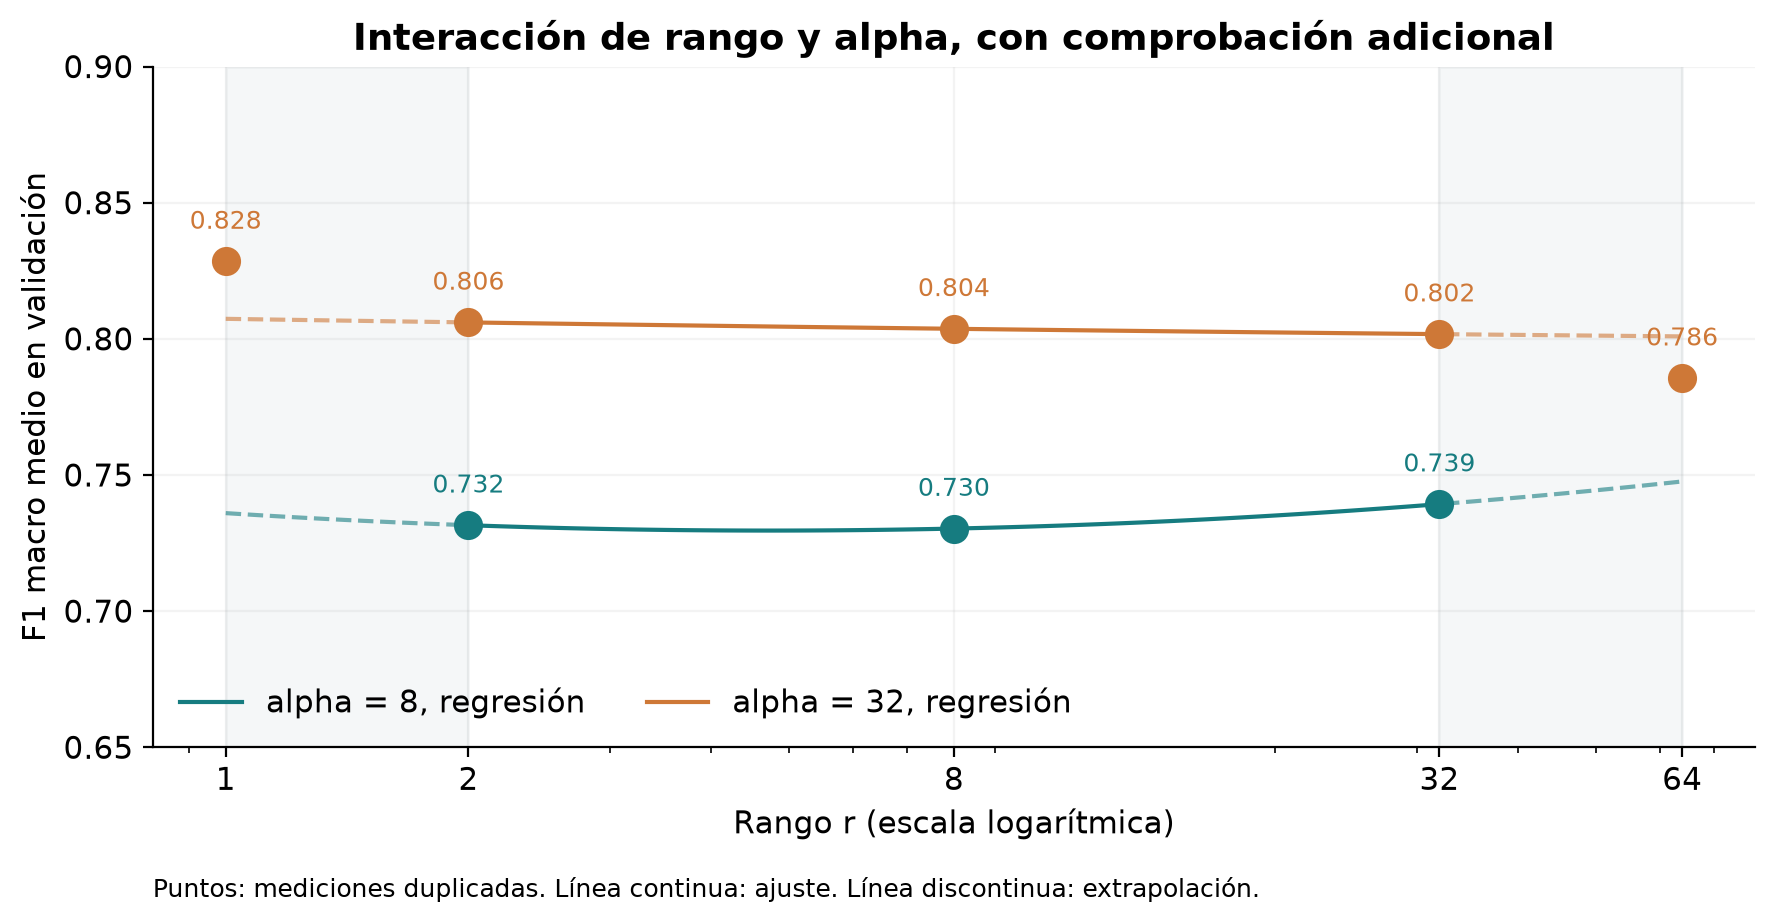

In [5]:
regression=read('regression.json')
print(regression['formula'])
print('Grados de libertad residuales:',regression['df_residual'])
print('R²:',round(regression['r2'],4),'RMSE residual:',round(regression['residual_rmse'],4))
display(pd.DataFrame(regression['effects']).round(5))
display(pd.DataFrame(regression['coefficients']).round(5))
display(Image(filename=str(F/'figures/factorial_interaction.png')))

## 5. Mejora marginal y frontera

Se fijó **0.02 de F1 macro** como mejora mínima de interés práctico. El remuestreo pareado conserva los mismos casos entre configuraciones y vuelve a muestrear las dos semillas disponibles. Se informa la diferencia al aumentar r y su incertidumbre.

Una p no significativa no demuestra que no haya mejora. Un límite superior unilateral del 95 % menor que 0.02 acota una mejora relevante bajo los casos y semillas observados. Con dos réplicas no se caracteriza toda la población de entrenamientos.

,alpha,rank_from,rank_to,delta,ci95,upper_one_sided95,rules_out_gain_over_delta
0,8,2,8,-0.001230,"[-0.048139010713572836, 0.04503474988493575]",0.036757,False
1,8,8,32,0.008981,"[-0.005410426100081136, 0.045457042957042906]",0.038918,False
2,32,1,2,-0.022384,"[-0.0839792632579569, 0.02906367163628527]",0.016784,True
3,32,2,8,-0.002343,"[-0.03945396122835426, 0.031606113126168116]",0.020178,False
4,32,8,32,-0.001957,"[-0.06443790516808685, 0.053627195679615214]",0.042447,False
5,32,32,64,-0.016174,"[-0.06823304865424441, 0.03335127830821421]",0.023110,False


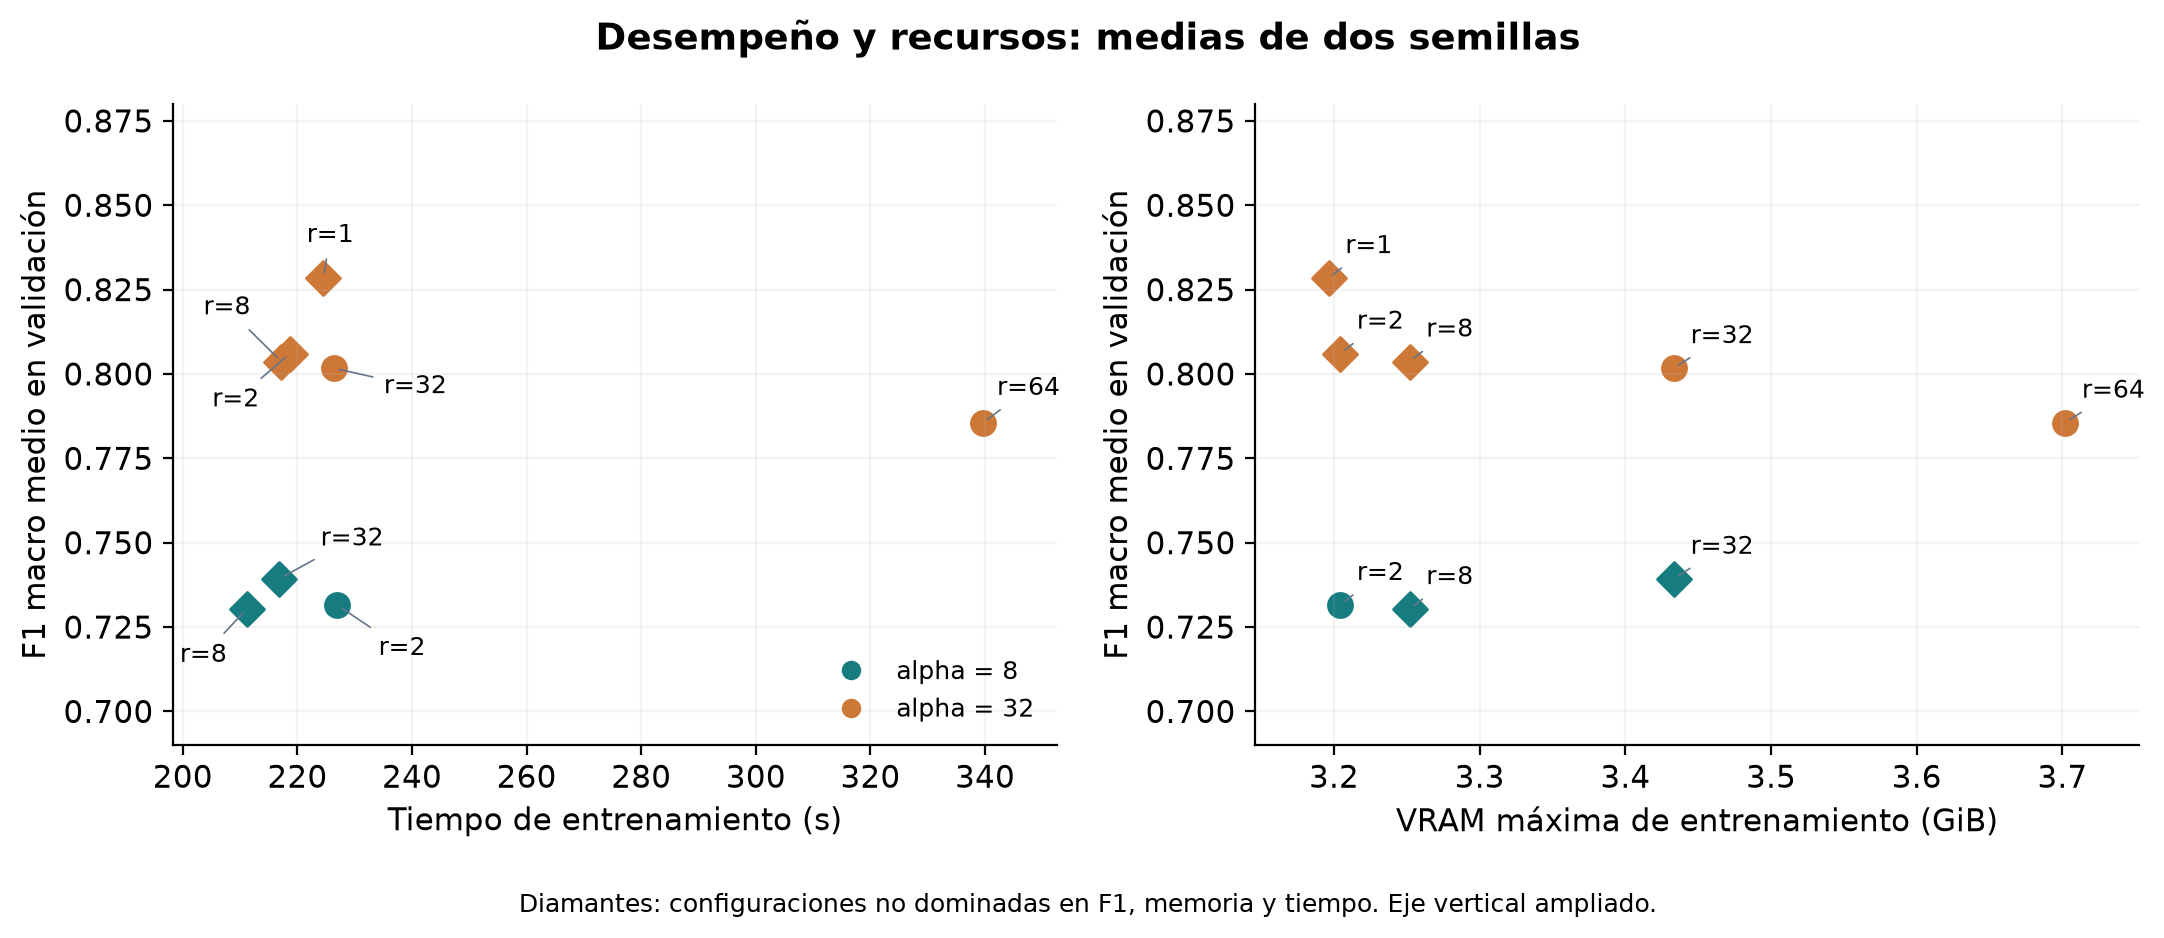

,rank,alpha,validation_f1,train_seconds,train_vram_gib,latency_s,pareto
0,1,32,0.8284,224.5388,3.1963,1.9743,True
1,2,8,0.7315,226.8938,3.2043,1.5290,False
2,2,32,0.8060,218.7125,3.2043,1.6410,True
3,8,8,0.7303,211.1268,3.2519,1.6142,True
4,8,32,0.8037,217.1870,3.2519,1.6340,True
5,32,8,0.7393,216.7830,3.4334,1.6362,True
6,32,32,0.8017,226.3682,3.4334,1.6459,False
7,64,32,0.7856,339.6710,3.7019,2.2560,False


In [6]:
gains=read('marginal_gains.json')
display(pd.DataFrame(gains['comparisons'])[['alpha','rank_from','rank_to','delta','ci95','upper_one_sided95','rules_out_gain_over_delta']])
display(Image(filename=str(F/'figures/factorial_resources.png')))
display(cells[cells.method=='lora'][['rank','alpha','validation_f1','train_seconds','train_vram_gib','latency_s','pareto']].round(4))

## 6. Óptimo teórico y comprobación real

La regresión busca un candidato en rangos enteros de 1 a 64. Si propone un rango nuevo, este se entrena por duplicado. Además se evalúa siempre r=64 con el alpha inicialmente seleccionado, fuera de [2,32]. La propuesta matemática queda guardada antes de las mediciones adicionales.

La elección práctica considera todas las validaciones medidas: se conservan las configuraciones a menos de 0.02 del máximo medio y se elige el menor rango; el tiempo medio resuelve empates. Esta tolerancia es una regla de decisión, no una prueba automática de equivalencia estadística.

In [7]:
theory=read('theoretical_optimum.json')
display(pd.DataFrame([theory['candidate']]))
additional=experiments[(experiments.method=='lora') & ~experiments['rank'].isin(plan['ranks'])]
display(additional[columns].sort_values(['rank','alpha','seed']).round(4))
display(pd.DataFrame(read('selection.json')['cells']).sort_values(['rank','alpha']).round(4))
display(Markdown(f"**Configuración seleccionada:** r={selection['rank']}, alpha={selection['alpha']}. F1 medio de validación: {selection['validation_f1']:.3f}."))

,rank,alpha,predicted_validation_f1
0,1,32,0.807341


,rank,alpha,seed,validation_f1,test_f1,schema,critical_recall,train_seconds,train_vram_gib,latency_s,warmup_seconds,cost_usd
12,1,32,42,0.8760,0.9046,1.0,0.9375,221.7653,3.1961,1.6363,0.9013,0.0616
13,1,32,43,0.7808,0.8784,1.0,0.8750,227.3123,3.1965,2.3122,0.8557,0.0631
14,64,32,42,0.8132,0.8608,1.0,0.8750,337.5444,3.7019,2.4882,1.3297,0.0938
15,64,32,43,0.7579,0.8593,1.0,0.8750,341.7976,3.7020,2.0239,1.3448,0.0949


,rank,alpha,validation_f1,train_seconds
0,1,32,0.8284,224.5388
1,2,8,0.7315,226.8938
2,2,32,0.8060,218.7125
3,8,8,0.7303,211.1268
4,8,32,0.8037,217.1870
5,32,8,0.7393,216.7830
6,32,32,0.8017,226.3682
7,64,32,0.7856,339.6710


**Configuración seleccionada:** r=1, alpha=32. F1 medio de validación: 0.828.

## 7. Comparación de tecnologías de PEFT

El LoRA seleccionado se compara con **DoRA**, **rsLoRA** y **LoRA+** de Hugging Face PEFT. Todos mantienen rango, alpha, datos, presupuesto y semillas 42 y 43.

| Método | Cambio e implementación |
|---|---|
| LoRA | Actualización de bajo rango, escala alpha/r. |
| DoRA | Separa magnitud y dirección. `use_dora=True`. |
| rsLoRA | Escala alpha/sqrt(r). `use_rslora=True`. |
| LoRA+ | Tasas distintas para A y B. `create_loraplus_optimizer` con razón B/A=16. |

LoRA+ usa AdamW, tasa máxima A=0.0002 y B=0.0032. El multiplicador coseno se aplica a cada grupo sin eliminar la razón de tasas. El código comprueba la razón 16 en cada paso y la guarda en el historial. Es una diferencia propia del método, no un cambio oculto. La configuración se comparte desde la selección de LoRA y no se optimiza por separado para cada tecnología.

Esta comparación está ejecutada, no es solo una propuesta. Los archivos de pesos de los adaptadores seleccionados se incluyen en la entrega. Los tiempos corresponden a adaptadores sin fusionar; una inferencia optimizada de DoRA requeriría medir la fusión por separado.

,method,n,validation_f1,test_f1,stress_f1,critical_recall,train_seconds,train_vram_gib,latency_s,cost_usd
0,lora,2,0.8284,0.8915,0.8468,0.9062,224.5388,3.1963,1.9743,0.0624
8,dora,2,0.8356,0.8896,0.9365,0.9062,652.6900,3.4763,12.3553,0.1813
9,rslora,2,0.8186,0.8830,0.8468,0.8750,323.5572,3.1873,2.0899,0.0899
11,loraplus,2,0.7041,0.7218,0.5239,0.9375,316.3802,3.1963,2.2146,0.0879


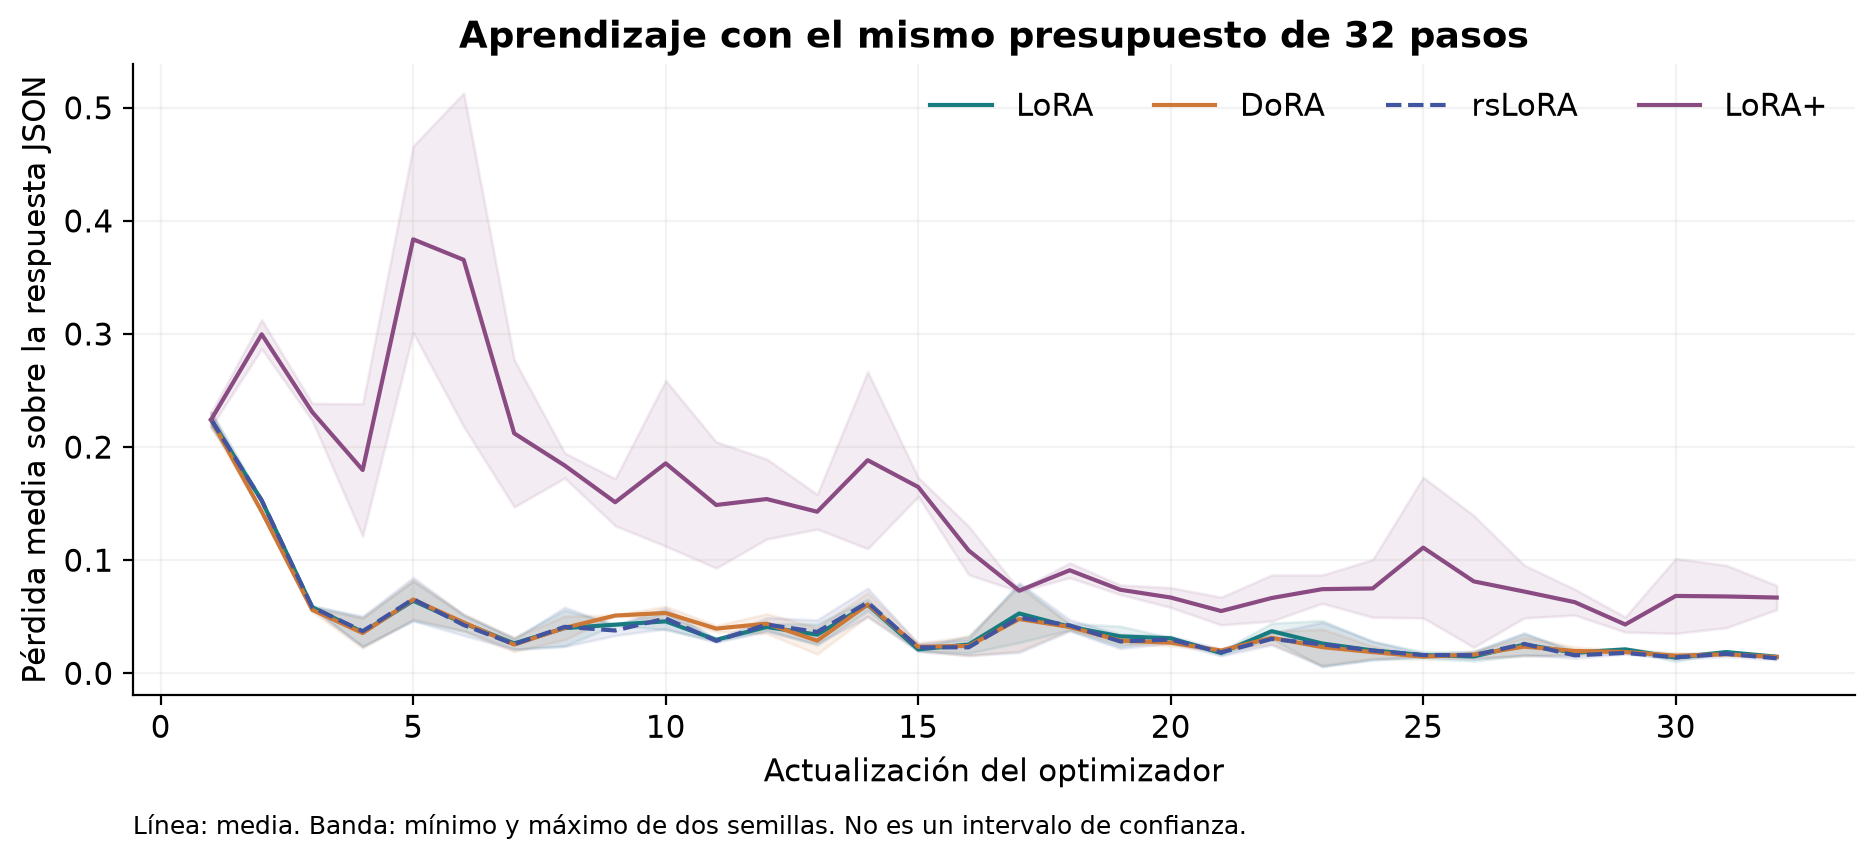

Con las mismas 32 actualizaciones, LoRA+ obtuvo F1 de prueba **0.722**, frente a **0.891** de LoRA. No se evaluó si otra razón de tasas o un entrenamiento más largo cambiaría el resultado. La curva y las métricas describen esta configuración concreta.

,method,seed,latency_s,mean_generated_tokens,generated_tokens_per_second,median_late_step_seconds,pipeline_cost_usd
12,lora,42,1.6363,31.4844,19.2411,6.8927,0.1235
13,lora,43,2.3122,31.4531,13.6030,7.0755,0.1446
16,dora,42,12.0852,31.4844,2.6052,20.6257,0.6156
17,dora,43,12.6254,31.4688,2.4925,20.6646,0.6332
18,rslora,42,2.0109,31.4688,15.6493,10.4668,0.1744
19,rslora,43,2.1689,31.4688,14.5089,9.9277,0.1703
20,loraplus,42,2.2140,31.5781,14.2626,9.9135,0.1717
21,loraplus,43,2.2152,31.5625,14.2482,9.9529,0.1728


El costo del proceso completo incluye carga, calentamiento y las tres evaluaciones, pero no cola ni confirmación nueva.


,delta,ci95,upper_one_sided95,n_cases,n_seeds,bootstrap,seed,caution
dora,0.003841,"[-0.01738908617681024, 0.027206826428619203]",0.023607,128,2,2000,20261023,Resampling only two observed training seeds ca...
rslora,0.020716,"[-0.007547612891690545, 0.05309699992552732]",0.046094,128,2,2000,20261023,Resampling only two observed training seeds ca...
loraplus,-0.125781,"[-0.20965494427925527, -0.03762988359156259]",-0.054971,128,2,2000,20261023,Resampling only two observed training seeds ca...


Intervalos exploratorios individuales, sin ajuste por tres comparaciones.
LoRA+, semilla 42 : razón B/A=16 verificada en los 32 pasos.
LoRA+, semilla 43 : razón B/A=16 verificada en los 32 pasos.


In [8]:
r,a=selection['rank'],selection['alpha']
tech=cells[(cells['rank']==r)&(cells.alpha==a)]
display(tech[['method','n','validation_f1','test_f1','stress_f1','critical_recall','train_seconds','train_vram_gib','latency_s','cost_usd']].round(4))
display(Image(filename=str(F/'figures/peft_training.png')))
base_row=tech[tech.method=='lora'].iloc[0];plus_row=tech[tech.method=='loraplus'].iloc[0]
display(Markdown(f"Con las mismas 32 actualizaciones, LoRA+ obtuvo F1 de prueba **{plus_row.test_f1:.3f}**, frente a **{base_row.test_f1:.3f}** de LoRA. No se evaluó si otra razón de tasas o un entrenamiento más largo cambiaría el resultado. La curva y las métricas describen esta configuración concreta."))
display(experiments[(experiments['rank']==r)&(experiments.alpha==a)][['method','seed','latency_s','mean_generated_tokens','generated_tokens_per_second','median_late_step_seconds','pipeline_cost_usd']].round(4))
print('El costo del proceso completo incluye carga, calentamiento y las tres evaluaciones, pero no cola ni confirmación nueva.')
display(pd.DataFrame({m:x for m,x in read('technology_comparisons.json')['comparisons'].items()}).T)
print('Intervalos exploratorios individuales, sin ajuste por tres comparaciones.')
for seed in [42,43]:
    name=f'fx_loraplus_r{r}_a{a}_s{seed}'
    history=read(name+'_training_history.json')
    ratios=[x['group_lrs'][2]/x['group_lrs'][0] for x in history]
    assert len(ratios)==32 and all(abs(x-16)<1e-9 for x in ratios)
    print('LoRA+, semilla',seed,': razón B/A=16 verificada en los 32 pasos.')

In [9]:
if selection['rank']==1:
    display(Markdown('**Control adicional de rsLoRA.** Con r=1 las escalas alpha/r y alpha/sqrt(r) coinciden. Las ejecuciones muestran diferencias, pero estas no pueden atribuirse al reescalamiento. Se fijaron las semillas sin forzar todos los kernels de CUDA a ser deterministas. Se entrenó rsLoRA también con r=32 y ambas semillas, donde las escalas sí difieren. Este control no cambia la selección. Véase la [documentación de reproducibilidad de PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html).'))
    display(pd.read_csv(R/'rslora_control_summary.csv')[['method','rank','alpha','n','validation_f1','test_f1','train_seconds','train_vram_gib']].round(4))

**Control adicional de rsLoRA.** Con r=1 las escalas alpha/r y alpha/sqrt(r) coinciden. Las ejecuciones muestran diferencias, pero estas no pueden atribuirse al reescalamiento. Se fijaron las semillas sin forzar todos los kernels de CUDA a ser deterministas. Se entrenó rsLoRA también con r=32 y ambas semillas, donde las escalas sí difieren. Este control no cambia la selección. Véase la [documentación de reproducibilidad de PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html).

,method,rank,alpha,n,validation_f1,test_f1,train_seconds,train_vram_gib
0,lora,1,32,2,0.8284,0.8915,224.5388,3.1963
1,lora,32,32,2,0.8017,0.8747,226.3682,3.4334
2,rslora,1,32,2,0.8186,0.8830,323.5572,3.1873
3,rslora,32,32,2,0.8238,0.8541,321.6774,3.4424


## 8. Comprobación con 128 casos nuevos

La prueba anterior ya había sido analizada en la etapa inicial. Por eso se agregó un conjunto nuevo, con familias de tareas separadas, abierto después de fijar hiperparámetros. Incluye 32 ejemplos por prioridad y mantiene la política original. No interviene en la selección ni en la regresión.

Se evalúa el modelo base y las dos réplicas de LoRA, DoRA, rsLoRA y LoRA+. El conjunto sigue siendo sintético: la comprobación no sustituye una evaluación con solicitudes reales y anotación independiente.

,condition,method,seed,f1,schema,critical_recall,exact,latency_s
0,base,base,NaN,0.7943,0.9609,0.8125,0.5703,2.0446
1,fx_lora_r1_a32_s42,lora,42.0,0.8161,1.0000,0.9062,0.7109,2.4080
2,fx_lora_r1_a32_s43,lora,43.0,0.8531,1.0000,0.8125,0.7969,2.3020
3,fx_dora_r1_a32_s42,dora,42.0,0.8161,1.0000,0.9062,0.7031,12.4417
4,fx_dora_r1_a32_s43,dora,43.0,0.8608,1.0000,0.8438,0.8047,12.3886
5,fx_rslora_r1_a32_s42,rslora,42.0,0.8347,1.0000,0.9062,0.7188,2.2971
6,fx_rslora_r1_a32_s43,rslora,43.0,0.8760,1.0000,0.9062,0.8281,2.3444
7,fx_loraplus_r1_a32_s42,loraplus,42.0,0.7165,1.0000,1.0000,0.5391,2.3261
8,fx_loraplus_r1_a32_s43,loraplus,43.0,0.7012,1.0000,0.8125,0.5938,2.3212


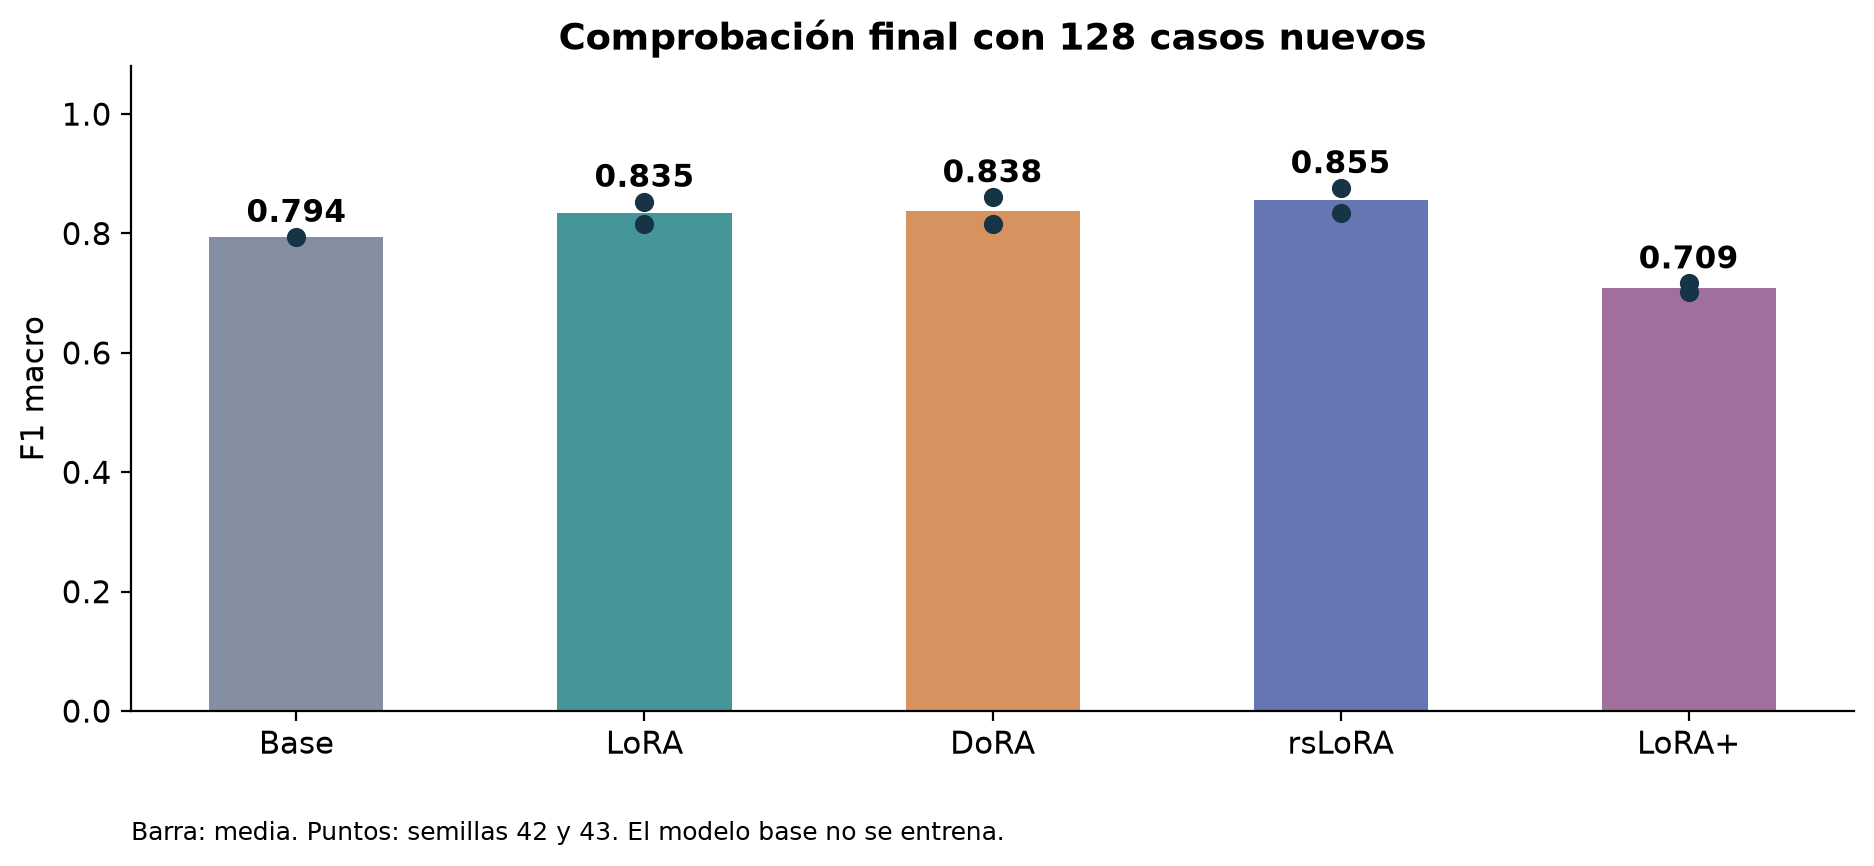

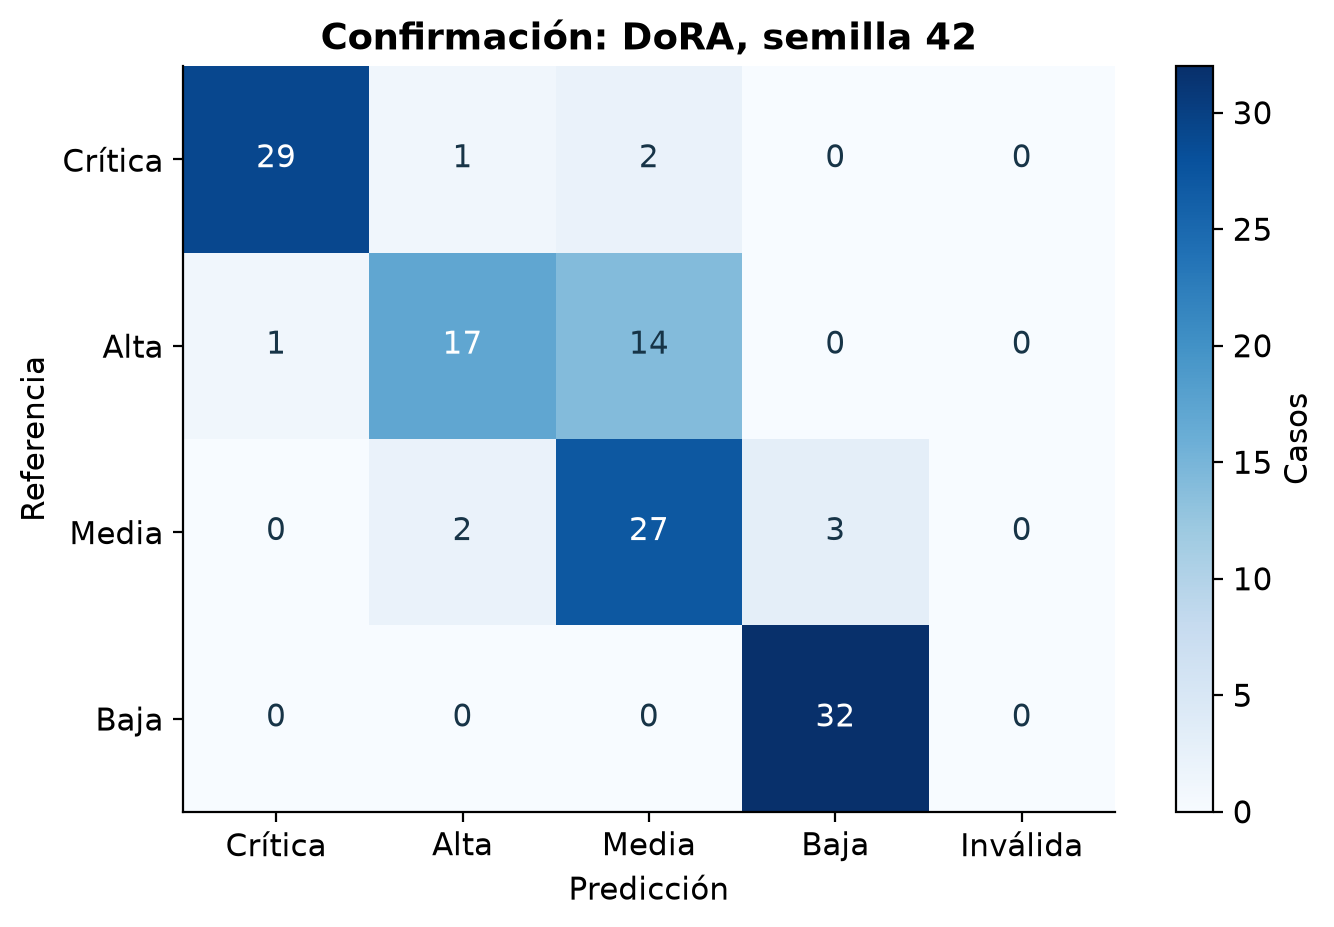

Caso: confirmation-0060 Necesitamos reparar el portal de compras institucionales; tenemos 120 horas de plazo. El impacto se considera bajo y alcanza a 120 personas. De este trabajo dependen 1 tareas. La tarea puede iniciarse; no tiene bloqueos previos. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Referencia: {'prioridad': 'critica', 'escalar': True, 'bloqueada': False, 'criterio': 'impacto'}
Respuesta: {"prioridad": "media", "escalar": false, "bloqueada": false, "criterio": "dependencia"}

Caso: confirmation-0078 Necesitamos recuperar el archivo de convenios internacionales; tenemos 8 horas de plazo. El impacto se considera medio y alcanza a 400 personas. De este trabajo dependen 8 tareas. La tarea puede iniciarse; no tiene bloqueos previos. El servicio está totalmente interrumpido. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa.
Ref

**Configuración recomendada:** LoRA con r=1 y alpha=32, elegido por validación según la tolerancia práctica fijada antes del experimento. Su F1 medio de validación es 0.828 y el de prueba 0.891.

Al pasar de r=1 a r=2 con alpha=32, la diferencia media en validación fue -0.022. Su límite superior unilateral del 95 % fue 0.017, menor que el margen práctico de 0.02. En este tramo, con los casos y semillas medidos, los resultados no justifican aumentar el rango para buscar una ganancia de 0.02 o más.

El máximo previsto por la superficie fue r=1, alpha=32, con F1 0.807. La comprobación real con dos semillas obtuvo 0.828. El modelo de regresión orienta la búsqueda, pero no reemplaza las mediciones.

En los 128 casos nuevos, el F1 fue 0.794 para base, 0.835 para LoRA y 0.838 para DoRA, promediando las dos réplicas de los adaptadores. DoRA necesitó 2.91 veces el tiempo de entrenamiento y 1.09 veces la VRAM de LoRA. La diferencia DoRA menos LoRA en confirmación fue +0.004, con intervalo del 95 % [-0.017, +0.027].

El óptimo y la frontera corresponden a la política sintética, 256 ejemplos de entrenamiento y 32 actualizaciones. No son límites universales de LoRA. Dos semillas y una GPU compartida restringen la precisión de las conclusiones.

**Comparación ampliada:** rsLoRA obtiene F1 0.855 y LoRA+ 0.709 en los 128 casos nuevos. Entre los métodos con rango y alpha compartidos, la mayor media de validación corresponde a DoRA. Las tasas de LoRA+ se mantienen en razón B/A=16 durante los 32 pasos. Estos métodos comparten la configuración seleccionada para LoRA; no se buscaron sus óptimos por separado. Los intervalos de las tres comparaciones son exploratorios y no están ajustados por multiplicidad.

Con r=1, las escalas alpha/r y alpha/sqrt(r) coinciden. Por eso las diferencias observadas entre LoRA y rsLoRA en ese rango no se atribuyen al reescalamiento. Se fijaron las semillas, pero no se forzó el uso exclusivo de kernels deterministas de CUDA. Se agregó una comparación duplicada de rsLoRA con r=32 frente al LoRA correspondiente del factorial, donde las escalas sí difieren. Sus resultados se conservan en rslora_control_summary.csv y no cambian la configuración compartida ni la selección con confirmación.

La mayor media descriptiva en la confirmación corresponde a rsLoRA (0.855), mientras que validación había elegido DoRA. No se cambia la selección usando este conjunto nuevo. El cambio de orden muestra la incertidumbre de comparar métodos con particiones pequeñas y dos semillas.

In [10]:
confirmation=pd.read_csv(R/'confirmation_summary.csv')
display(confirmation.round(4))
display(Image(filename=str(F/'figures/confirmation.png')))
display(Image(filename=str(F/'figures/confirmation_confusion.png')))
best_method=read('technology_selection.json')['best_validation_method']
best_name=f'fx_{best_method}_r{selection["rank"]}_a{selection["alpha"]}_s42'
errors=read('confirmation_errors.json')[best_name]
for row in errors:
    print('Caso:',row['id'],row['input'])
    print('Referencia:',row['truth'])
    print('Respuesta:',row['raw'])
    print()
display(Markdown((F/'conclusion.md').read_text(encoding='utf8')))

## 9. Reproducibilidad y alcance

Para repetir la ampliación, enviar `sbatch run_factorial.slurm` en Khipu con un directorio de resultados vacío o una copia del proyecto. Enviar luego `sbatch --dependency=afterok:ID_FACTORIAL run_peft.slurm`, sustituyendo ID_FACTORIAL por el identificador devuelto por Slurm. Al terminar ambos trabajos, ejecutar `python src/factorial_analysis.py` para reconstruir tablas y figuras. El código verifica las doce condiciones, las dos semillas y la correspondencia de cada respuesta con el dato original.

El óptimo se limita a esta tarea, este presupuesto y el dominio medido. No demuestra un límite universal de LoRA. La incertidumbre por dos semillas, el origen sintético y la GPU compartida restringen las conclusiones. Todos los registros y las predicciones se conservan; la entrega incluye los pesos de los adaptadores elegidos.

Fuentes: transcripción facilitada del [video sobre diseños factoriales](https://www.youtube.com/watch?v=EYKfpKXErtQ), [Qwen3.5-4B](https://huggingface.co/Qwen/Qwen3.5-4B), [PEFT](https://huggingface.co/docs/peft/en/package_reference/lora) y material del docente en `originales/`.